# 09 · Measuring ANN without fooling ourselves

## The engineering question
Is a fast approximate request actually exercising a built index, and how much nearest-neighbor fidelity does it lose?

**Learning outcomes:** distinguish HNSW build parameters from query effort; wait for indexed-vector coverage; compare against an identical eligible exhaustive oracle; separate warm request latency, ingestion, and index construction; qualify search-mode claims.

HNSW connects nearby vectors in a navigable graph. More edges (`m`) and construction effort can improve graph quality at a memory/build cost. Query effort (`hnsw_ef`) trades search work for fidelity. This lab rebuilds two deliberately small graphs over 6,000 synthetic 64-dimensional vectors, then varies query effort. The exact NumPy oracle uses the same vectors and filter. Synthetic ANN recall says nothing about semantic usefulness.

**Validity gate:** at least 99% indexed vectors, green status, low full-scan threshold, sufficient corpus size, and explicit approximate requests. The pinned API does not expose a per-query execution trace. These controls make HNSW eligible; behavioral changes support that interpretation, but we cannot prove every request followed the same execution path. Selective filters can legitimately choose another strategy.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("09", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,m,write_seconds,post_write_index_wait_seconds,indexed_vectors
0,8,0.300646,1.056393,6000
1,16,0.341193,1.047779,6000


,eligible_points,m,hnsw_ef,ann_recall,median_ms,p95_ms
0,60,8,8,0.985,1.174208,6.378775
1,60,8,32,1.000,1.193084,1.770967
2,60,8,128,1.000,1.475854,3.425438
3,60,16,8,0.990,1.723542,3.596604
4,60,16,32,1.000,1.218916,1.551073
5,60,16,128,1.000,2.538896,12.983933
6,6000,8,8,0.240,2.794501,6.369534
7,6000,8,32,0.550,2.439334,4.459256
8,6000,8,128,0.850,1.390791,2.526362
9,6000,16,8,0.470,1.204730,2.152631


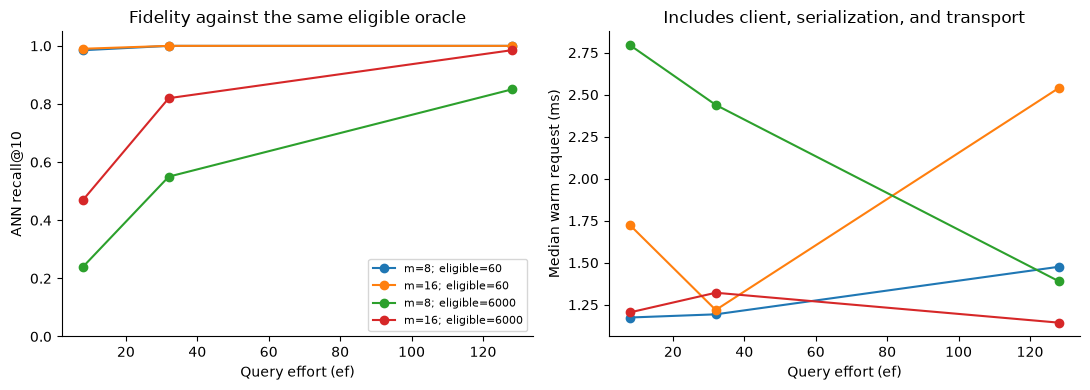

In [2]:
import time
from uuid import uuid4
from qdrant_client import QdrantClient, models as qm
from vector_masterclass.config import qdrant_url
from vector_masterclass.evidence import json_write
from vector_masterclass.metrics import ann_recall

rng = np.random.default_rng(17)
vectors = rng.normal(size=(6000, 64)).astype("float32")
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
query_vectors = rng.normal(size=(20, 64)).astype("float32")
query_vectors /= np.linalg.norm(query_vectors, axis=1, keepdims=True)
rows, builds = [], []
client = QdrantClient(url=qdrant_url(), timeout=30)
for m in [8, 16]:
    name = "vmc_09_" + uuid4().hex[:8]
    client.create_collection(
        name,
        vectors_config=qm.VectorParams(size=64, distance=qm.Distance.COSINE),
        hnsw_config=qm.HnswConfigDiff(m=m, ef_construct=40, full_scan_threshold=10),
        optimizers_config=qm.OptimizersConfigDiff(indexing_threshold=64, default_segment_number=1),
    )
    try:
        client.create_payload_index(name, "bucket", qm.PayloadSchemaType.INTEGER, wait=True)
        started = time.perf_counter()
        for first in range(0, len(vectors), 500):
            client.upsert(
                name,
                points=[
                    qm.PointStruct(id=i, vector=vectors[i].tolist(), payload={"bucket": i % 100})
                    for i in range(first, first + 500)
                ],
                wait=True,
            )
        write_seconds = time.perf_counter() - started
        deadline = time.monotonic() + 60
        while time.monotonic() < deadline:
            info = client.get_collection(name)
            if info.status == qm.CollectionStatus.GREEN and (
                info.indexed_vectors_count or 0
            ) >= 0.99 * len(vectors):
                break
            time.sleep(0.25)
        else:
            raise TimeoutError("Index validity gate failed; no ANN claim is allowed")
        builds.append(
            {
                "m": m,
                "write_seconds": write_seconds,
                "post_write_index_wait_seconds": time.perf_counter() - started - write_seconds,
                "indexed_vectors": info.indexed_vectors_count,
            }
        )
        json_write(lesson.path / f"index-m{m}.json", info.model_dump(mode="json"))
        for upper in [100, 1]:
            eligible = (
                np.arange(len(vectors))
                if upper == 100
                else np.flatnonzero(np.arange(len(vectors)) % 100 < upper)
            )
            policy = (
                None
                if upper == 100
                else qm.Filter(must=[qm.FieldCondition(key="bucket", range=qm.Range(lt=upper))])
            )
            oracles = []
            for vector in query_vectors:
                expected = eligible[
                    np.argsort(-(vectors[eligible] @ vector), kind="stable")[:10]
                ].tolist()
                exact = client.query_points(
                    name,
                    query=vector.tolist(),
                    query_filter=policy,
                    limit=10,
                    search_params=qm.SearchParams(exact=True),
                ).points
                assert set(expected) == {p.id for p in exact}
                oracles.append(expected)
            for ef in [8, 32, 128]:
                # One unmeasured warm-up for each configuration.
                client.query_points(
                    name,
                    query=query_vectors[0].tolist(),
                    query_filter=policy,
                    limit=10,
                    search_params=qm.SearchParams(hnsw_ef=ef),
                )
                for qi, (vector, oracle) in enumerate(zip(query_vectors, oracles)):
                    started = time.perf_counter()
                    hits = client.query_points(
                        name,
                        query=vector.tolist(),
                        query_filter=policy,
                        limit=10,
                        search_params=qm.SearchParams(hnsw_ef=ef, exact=False),
                    ).points
                    rows.append(
                        {
                            "m": m,
                            "hnsw_ef": ef,
                            "eligible_points": len(eligible),
                            "query": qi,
                            "milliseconds": (time.perf_counter() - started) * 1000,
                            "ann_recall": ann_recall([h.id for h in hits], oracle, 10),
                        }
                    )
    finally:
        client.delete_collection(name)
client.close()
results = lesson.table(pd.DataFrame(rows))
display(lesson.table(pd.DataFrame(builds), "builds"))
summary = (
    results.groupby(["eligible_points", "m", "hnsw_ef"])
    .agg(
        ann_recall=("ann_recall", "mean"),
        median_ms=("milliseconds", "median"),
        p95_ms=("milliseconds", lambda s: s.quantile(0.95)),
    )
    .reset_index()
)
display(lesson.table(summary, "summary"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (eligible, m), group in summary.groupby(["eligible_points", "m"]):
    label = f"m={m}; eligible={eligible}"
    axes[0].plot(group.hnsw_ef, group.ann_recall, "o-", label=label)
    axes[1].plot(group.hnsw_ef, group.median_ms, "o-", label=label)
axes[0].set(
    xlabel="Query effort (ef)",
    ylabel="ANN recall@10",
    ylim=(0, 1.05),
    title="Fidelity against the same eligible oracle",
)
axes[1].set(
    xlabel="Query effort (ef)",
    ylabel="Median warm request (ms)",
    title="Includes client, serialization, and transport",
)
axes[0].legend(fontsize=8)
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
A flat latency line is a valid result on this small local corpus: client/transport overhead can dominate graph work. Recall need not increase monotonically for each individual query. The small filtered subset may show perfect recall because a scan is suitable; do not label that row as traced graph execution. Index builds can vary with insertion/concurrency, so record configuration and distributions instead of promising identical scores on every rerun.

**Exercise:** increase `ef_construct` while holding m and query effort fixed. Predict what changes at ingestion versus serving. Then explain why comparing a filtered ANN query to an unfiltered exact oracle gives a misleading recall number.

Production evaluation requires representative dimensions, distributions, update traffic, filter selectivity, and enough repeated queries for uncertainty estimates. The twenty-query p95 here is descriptive and statistically weak. [Qdrant indexing concepts](https://qdrant.tech/documentation/concepts/indexing/).

In [3]:
manifest = lesson.finish(
    {
        "index_gate_passed": all(b["indexed_vectors"] >= 5940 for b in builds),
        "all_controls_measured": len(results) == 240,
        "recall_valid": bool(results.ann_recall.between(0, 1).all()),
    },
    observations={
        "search_mode_evidence": "configuration, index state, and observed behavior; no per-query trace",
        "synthetic": True,
        "semantic_claim": False,
    },
)

{
  "artifact": "artifacts/20261031T043206Z-e31340/09",
  "checks": {
    "index_gate_passed": true,
    "all_controls_measured": true,
    "recall_valid": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.